# Titanic Surivial Data

This notebook will train and evalute the Titanic Dataset using **pandas** and **matplotlib**. To predict the surivial outcome of a passenger.

The following models will be used: 
- **Logistic Regression**
- **Random Forest**


## 1. Import Libraries

- I used the following libraries to handle, evaluate and model the dataset:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score,confusion_matrix,classification_report



# **Citations**

I used the following tutorials to learn how to use pandas and classification and confusion matrix:

- https://www.geeksforgeeks.org/pandas/python-pandas-dataframe/
- https://www.geeksforgeeks.org/python/how-to-drop-one-or-multiple-columns-in-pandas-dataframe/
- https://www.geeksforgeeks.org/data-analysis/working-with-missing-data-in-pandas/
- https://www.geeksforgeeks.org/machine-learning/handling-missing-values-machine-learning/
- https://www.statology.org/label-encoding-in-python/
- https://www.geeksforgeeks.org/machine-learning/compute-classification-report-and-confusion-matrix-in-python/
- https://www.geeksforgeeks.org/machine-learning/macro-average-vs-weighted-average/


# 2. Import Data

- I used pandas to import the csv to be able to use the data.
    - At first I tried to use numpy but I found it to hard to be able to get the program to properly read in the data correctly.


In [4]:
#When importing I kept getting a ValueError on Line 4, after some time and removing and inserting code for the genfromtxt.
#I realised the error was being caused by the delimiter while the features are separated by a comma, the data also has text that uses double qoutes "", so I had to set the delimiter as '","' for it to work. 
#data_np = np.genfromtxt("train.csv", delimiter= ',',dtype=None,skip_header=True)

#I still kept getting errors in the data with numpy so I switched to using pandas to import the data. I found pandas a lot eaiser to work with the numpy.

# Reads the data train.csv into the program
data = pd.read_csv("train.csv")

# I then convert my dataset into a DataFrame which turns data into a 2-D table, making it easier to view and manipulate the data.
train_data = pd.DataFrame(data)

#.head() allows me to view the first five rows of data to see my data. 
train_data.head(6)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


# 3. Data cleaning and Wrangling.

To use the dataset I first need to **clean** and **wrangle** the data. This process means filling in missing values, removing unnecessary columns, and encoding data.

#### Missing Values: 

- **Age** is the only column with missing Data.I used  **Median**  to fill in the missing data as it is better for skewed data. I first used **Mean** but data using mean can be skewed by outliers.
#### Removing Unnecessary Data:

- At first I only removed the survived column as this is my target feature. But the more I worked with the data I realised that I had more unnecessary columns that I could remove and still accurately predict an outcome. So I removed: 
     - **Survived** - Traget feature.
     - **Passenger ID** - Unique ID for each Passenger, not need for prediction.
     - **Name** - Passenger name has no impact on survival.
     - **Ticket** - Ticket number is random and has to impact on survival.
     - **Cabin** - Many missing values and a mix of string and numerical data, which I found hard to encode, but I realised that I didn't need it at all to predict survival.
     - **Fare** - Price of ticket did not matter.

##### Encoding Data:

- To train the models I had to remove Categorical Data from my dataset, as models need to be trained on numerical data to be able to use the data to predict the survival outcome. To do this I used **LabelEncoder** to convert the data for the models.

In [5]:
#I used df.drop to remove the Survived col from the data. Also name,ticket and cabin
X = train_data.drop(["PassengerId","Survived","Name","Ticket","Cabin","Fare"],axis =1)
#The reason for dropping Survived above,is so I can use Survived for the Target feature in which I will use to predict the survial of passengers based on the other features
y = train_data["Survived"]
#I now had to clean the data as there is missing data in age
age_median = X["Age"].median().round(0)
#fare_fill = X["Fare"].median().round(2), I ended up dropping fare so this code was not needed
#cabin_fill = X["Cabin"].fillna("Unknown") I also dropped cabin.

# I used LabelEnconder to convert my categorical data Sex and Embarked so the data can be used for the models
label_en = LabelEncoder()
# male = 1. female = 0
X["Sex"] = label_en.fit_transform(X["Sex"])
# C = 0. Q = 1. S = 2.
X["Embarked"] = label_en.fit_transform(X["Embarked"])
#I create a variable for my cleaned data called X_clean that is my X data with my Age column filled in.
X_clean = X.fillna({"Age": age_median})
#X_clean will now be the dataset I use for traing and testing the data, which will then be used to train the models
X_clean.head()


,Pclass,Sex,Age,SibSp,Parch,Embarked
0,3,1,22.0,1,0,2
1,1,0,38.0,1,0,0
2,3,0,26.0,0,0,2
3,1,0,35.0,1,0,2
4,3,1,35.0,0,0,2


## 4. Train and Test Data

- Here I will split my X_clean dataset for training and testing. Which is an important step that needs to be done before you can train your models.

In [6]:
#I used train_test_split to split my data into 20% test and 80% train split. It splits my X_clean(features) into two set X_train and X_test and y(target feature for predicting survival) will be split into y_train and y_test.
# stratify= y ensures balance in the training and testing datasets, this means that the distrubtion of 0 and 1s will be even amoung the training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(X_clean, y, test_size=0.2, random_state=42,stratify= y)
#prints the shape of the X_train shape
print("Train set:", X_train.shape)


Train set: (712, 6)


# 5. Train Models

- I will the following two models to train the test data X_train and y_train:
    - **LogisticRegression** - Classification model to predict a binary 0 or 1 outcome.
    - **RandomForestClassifier** - Uses decision trees to predict better outcomes.

In [7]:
#I initialize it with a maximum of 300 iterations for training. I picked 300 at random.
logical_regress = LogisticRegression(max_iter=300)
#.fit() will now train the LogisticRegression model on the training data X_train and y_train
#I ran into a problem at first when I was trying to train the data. I  got a "ValueError: Found input variables with inconsistent numbers of samples: [891, 712]"
#but after going over the program I realised I was using the wrong X data. I was using X_clean instead of X_train.
logical_regress.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [8]:
#I initialize it to have 100 decision trees and a random state of 42 to ensure the output is the same every time that the model is trained.
ranf_model = RandomForestClassifier(n_estimators=100, random_state= 42)
#.fit() again will train the model but this time it will train the RandomForestClassifier.
ranf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

# 6. Evaluate Models

Once the models have been trained, I have to evaluate the performance on the test data.

I will use the following metrics:
- **Accuracy** - Measures the amount of correct predictions out of all predictions made.
- **Precision** - Measures the amount of true positives, survivors, against all predictied positives.
- **Classification report** - Detailed report of metrics, **precision**, **recall**, **f1-score**, **support**

In [9]:
#Logical Regression
#To make the following readable I broke up the code into sections for readabilty.
# A line of dashes for the heading before and after.
print("-"*60)
# used F-string to center the heading.
print(f"{"Logical Regression":^50}")
print("-"*60)

#Using the trained model from above logical_regress .predict(X_test) gives the predictions from the model.
log_pred = logical_regress.predict(X_test)
#accuracy_score uses the target value y_test which has the values on survival to compare to the log_pred predictions, which has predicted the survival.
print("Logistic Regression Accuracy: ", accuracy_score(y_test, log_pred))
#precision_score compares the target value y_test which has the true values on survival against the predicted values of survival to see how precise the model is.
print("Logistic Regression Precision: ", precision_score(y_test, log_pred))
print("-"*60)
#The report allows be to view a detailed breakdown of the models performance. I use the target names Not survived = 0 and Survied = 1
print(f"{"Logistic Regression Classification Report:":^50}\n ", "\n",classification_report(y_test, log_pred,target_names=["Not Survived", "Survied"]))

------------------------------------------------------------
                Logical Regression                
------------------------------------------------------------
Logistic Regression Accuracy:  0.8044692737430168
Logistic Regression Precision:  0.7931034482758621
------------------------------------------------------------
    Logistic Regression Classification Report:    
  
               precision    recall  f1-score   support

Not Survived       0.81      0.89      0.85       110
     Survied       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



In [10]:
#RandomForestClassifier
#To make the following readable I broke up the code into sections for readabilty.
# A line of dashes for the heading before and after.
#Using the trained model from above ranf_model .predict(X_test) gives the predictions from the model.
print("-"*60)
print(f"{"Random Forest":^50}")
print("-"*60)
ran_pred = ranf_model.predict(X_test)
#accuracy_score uses the target value y_test which has the values on survival to compare to the ran_pred predictions, which has predicted the survival.
print("Random Forest Accuracy: ", accuracy_score(y_test, ran_pred))
#precision_score compares the target value y_test which has the true values on survival against the predicted values of survival to see how precise the model is.
print("Random Forest Precision: ", precision_score(y_test, ran_pred))
print("-"*60)
#The report allows be to view a detailed breakdown of the models performance. I use the target names Not survived = 0 and Survied = 1
#classification_report gives more metrics:
#Percision - how many predicted passengers actually survived. 
#Recall - how many real passengers survived or not and the model correctly idenify them.
#F1- score is a score of precision and recall calculated for balance. 
#Support- the number of true samples in each class of y_test.
#accuracy - total correct predictions
#macro avg - Equal class weighing 
#weighted avg = weighted by class size
print("Random Forest Classification Report:\n ", classification_report(y_test, ran_pred,target_names=["Not Survived", "Survied"]))
print("-"*60)

------------------------------------------------------------
                  Random Forest                   
------------------------------------------------------------
Random Forest Accuracy:  0.7932960893854749
Random Forest Precision:  0.75
------------------------------------------------------------
Random Forest Classification Report:
                precision    recall  f1-score   support

Not Survived       0.82      0.85      0.84       110
     Survied       0.75      0.70      0.72        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179

------------------------------------------------------------


# 7. Confusion Matrix
I will use Confusion Matrix to compare the predicted outcomes of survival to the actual outcomes of survial.

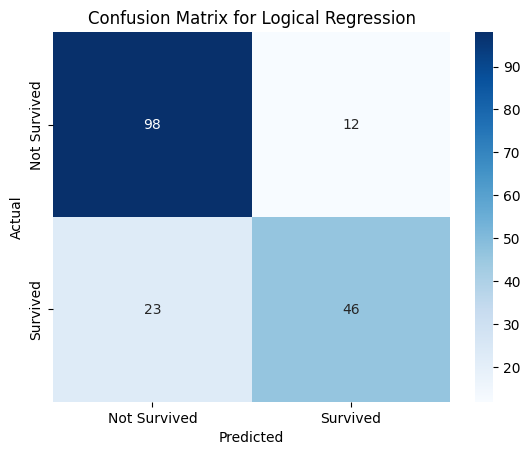

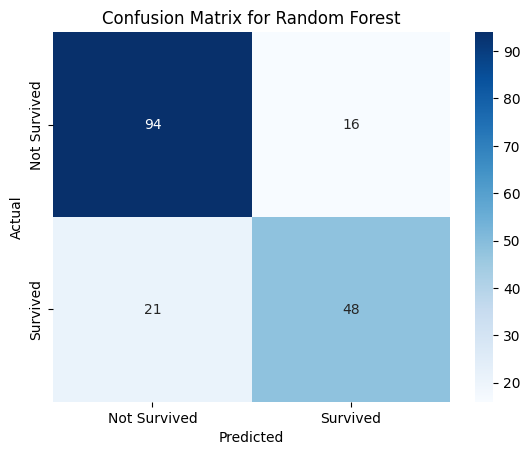

In [11]:
#Logical Regression 
#I use my trained log_pred from the evaluate models section to use with my y_test to see the predictions by the model compared to the true data in y
log_cm = confusion_matrix(y_test, log_pred)
sns.heatmap(log_cm, annot=True, fmt="", cmap="Blues", xticklabels=["Not Survived","Survived"],yticklabels=["Not Survived","Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Logical Regression")
plt.show()

#Random Forest
#I again use my trained model ran_pred to compare the predicted survival against the y_test which has the survival of the real passengers
ran_cm = confusion_matrix(y_test, ran_pred)
sns.heatmap(ran_cm, annot=True, fmt="", cmap="Blues", xticklabels=["Not Survived","Survived"],yticklabels=["Not Survived","Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Random Forest")
plt.show()


# 8. Save Data Model

I will save the Data model to use with the Demo Application.

In [12]:
joblib.dump(logical_regress, "Titanic_prediction_model.joblib")
print("Saved Logic Regression model to Titanic_prediction_model.joblib")

Saved Logic Regression model to Titanic_prediction_model.joblib
